In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Locate repository root
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/processed/training_handoff/development.csv").exists()
)

# Load development data only
df = pd.read_csv(
    ROOT / "data/processed/training_handoff/development.csv"
)

# Ensure chronological order
df = df.sort_values("poster_year").reset_index(drop=True)

y = df["y_active_mid_count"]

print("Development observations:", len(df))

Development observations: 51


In [2]:
tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=5,
    gap=1
)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(df), start=1
):
    train_years = df.iloc[train_idx]["poster_year"]
    val_years = df.iloc[val_idx]["poster_year"]

    print(
        f"Fold {fold}: "
        f"Train {train_years.min()}-{train_years.max()}, "
        f"Validate {val_years.min()}-{val_years.max()}"
    )

Fold 1: Train 1949-1973, Validate 1975-1979
Fold 2: Train 1949-1978, Validate 1980-1984
Fold 3: Train 1949-1983, Validate 1985-1989
Fold 4: Train 1949-1988, Validate 1990-1994
Fold 5: Train 1949-1993, Validate 1995-1999


In [3]:
fold_results = []
all_predictions = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(df), start=1
):
    # Split target into training and validation
    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Calculate mean using training data only
    train_mean = y_train.mean()

    # Predict the training mean for every validation year
    y_pred = np.full(len(y_val), train_mean)

    # Evaluate predictions
    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    fold_results.append({
        "fold": fold,
        "train_mean": train_mean,
        "MAE": mae,
        "RMSE": rmse
    })

    for idx, actual, pred in zip(val_idx, y_val, y_pred):
        all_predictions.append({
            "target_year": df.loc[idx, "target_year"],
            "actual": actual,
            "predicted": pred
        })

results = pd.DataFrame(fold_results)
predictions = pd.DataFrame(all_predictions)

display(results.round(3))

,fold,train_mean,MAE,RMSE
0,1,4.440,2.440,2.675
1,2,4.000,2.200,2.324
2,3,3.657,2.531,2.712
3,4,3.600,1.680,2.098
4,5,3.400,1.040,1.131


In [4]:
overall_mae = mean_absolute_error(
    predictions["actual"],
    predictions["predicted"]
)

overall_rmse = np.sqrt(mean_squared_error(
    predictions["actual"],
    predictions["predicted"]
))

print(f"Overall MAE: {overall_mae:.3f}")
print(f"Overall RMSE: {overall_rmse:.3f}")

Overall MAE: 1.978
Overall RMSE: 2.262


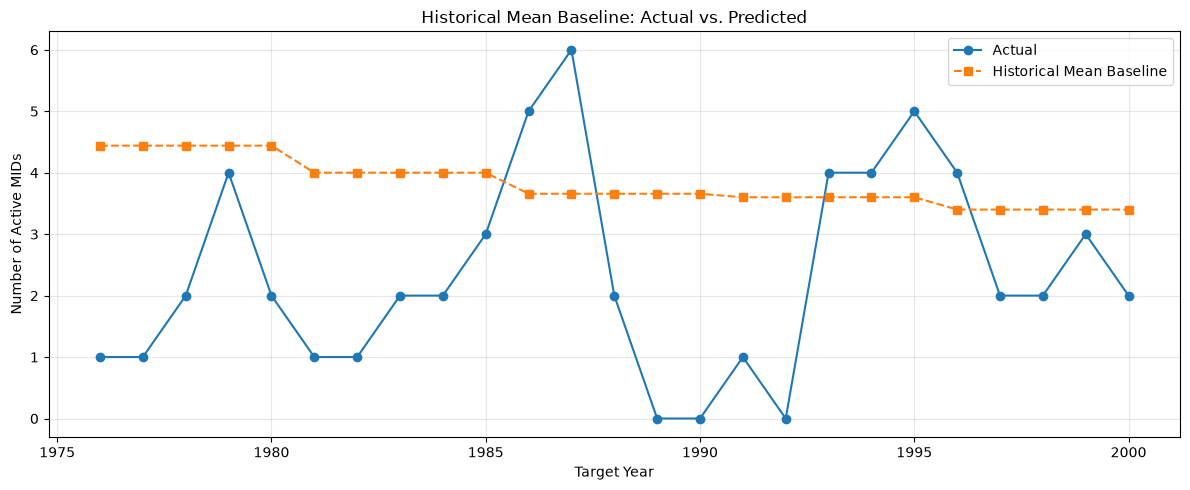

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    predictions["target_year"],
    predictions["actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    predictions["target_year"],
    predictions["predicted"],
    marker="s",
    linestyle="--",
    label="Historical Mean Baseline"
)

plt.xlabel("Target Year")
plt.ylabel("Number of Active MIDs")
plt.title("Historical Mean Baseline: Actual vs. Predicted")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Previous year's dispute count
df["y_previous"] = y.shift(1)

display(
    df[[
        "poster_year",
        "target_year",
        "y_active_mid_count",
        "y_previous"
    ]].head(10)
)

/var/folders/3r/t9_sf_zx0v5g1db_1689z1hc0000gn/T/ipykernel_26631/2146828674.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["y_previous"] = y.shift(1)


,poster_year,target_year,y_active_mid_count,y_previous
0,1949,1950,6,NaN
1,1950,1951,3,6.0
2,1951,1952,3,3.0
3,1952,1953,5,3.0
4,1953,1954,6,5.0
5,1954,1955,6,6.0
6,1955,1956,6,6.0
7,1956,1957,1,6.0
8,1957,1958,4,1.0
9,1958,1959,5,4.0


In [7]:
persistence_results = []
persistence_predictions = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(df), start=1
):
    # Actual dispute counts
    y_val = y.iloc[val_idx]

    # Predict using the previous year's actual count
    y_pred = df["y_previous"].iloc[val_idx]

    # Evaluate
    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    persistence_results.append({
        "fold": fold,
        "MAE": mae,
        "RMSE": rmse
    })

    for idx, actual, pred in zip(val_idx, y_val, y_pred):
        persistence_predictions.append({
            "target_year": df.loc[idx, "target_year"],
            "actual": actual,
            "predicted": pred
        })

persistence_results = pd.DataFrame(persistence_results)
persistence_predictions = pd.DataFrame(persistence_predictions)

display(persistence_results.round(3))


,fold,MAE,RMSE
0,1,1.0,1.342
1,2,0.6,0.775
2,3,1.8,2.236
3,4,1.4,1.949
4,5,1.0,1.183


In [8]:
persistence_mae = mean_absolute_error(
    persistence_predictions["actual"],
    persistence_predictions["predicted"]
)

persistence_rmse = np.sqrt(mean_squared_error(
    persistence_predictions["actual"],
    persistence_predictions["predicted"]
))

print(f"Overall MAE: {persistence_mae:.3f}")
print(f"Overall RMSE: {persistence_rmse:.3f}")

Overall MAE: 1.160
Overall RMSE: 1.587


In [9]:
fixed_results = []
fixed_predictions = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(df), start=1
):
    y_val = y.iloc[val_idx]

    # Last observed outcome from the training fold
    last_train_count = y.iloc[train_idx[-1]]

    # Keep that prediction fixed across the validation block
    y_pred = np.full(len(val_idx), last_train_count)

    fixed_results.append({
        "fold": fold,
        "MAE": mean_absolute_error(y_val, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, y_pred))
    })

    fixed_predictions.extend(
        zip(y_val.to_numpy(), y_pred)
    )

display(pd.DataFrame(fixed_results).round(3))

actual_fixed, predicted_fixed = np.array(fixed_predictions).T

print(
    "Fixed-origin MAE:",
    round(mean_absolute_error(actual_fixed, predicted_fixed), 3)
)
print(
    "Fixed-origin RMSE:",
    round(np.sqrt(mean_squared_error(
        actual_fixed, predicted_fixed
    )), 3)
)

,fold,MAE,RMSE
0,1,2.0,2.280
1,2,2.2,2.324
2,3,2.2,2.569
3,4,2.8,3.406
4,5,1.4,1.612


Fixed-origin MAE: 2.12
Fixed-origin RMSE: 2.506


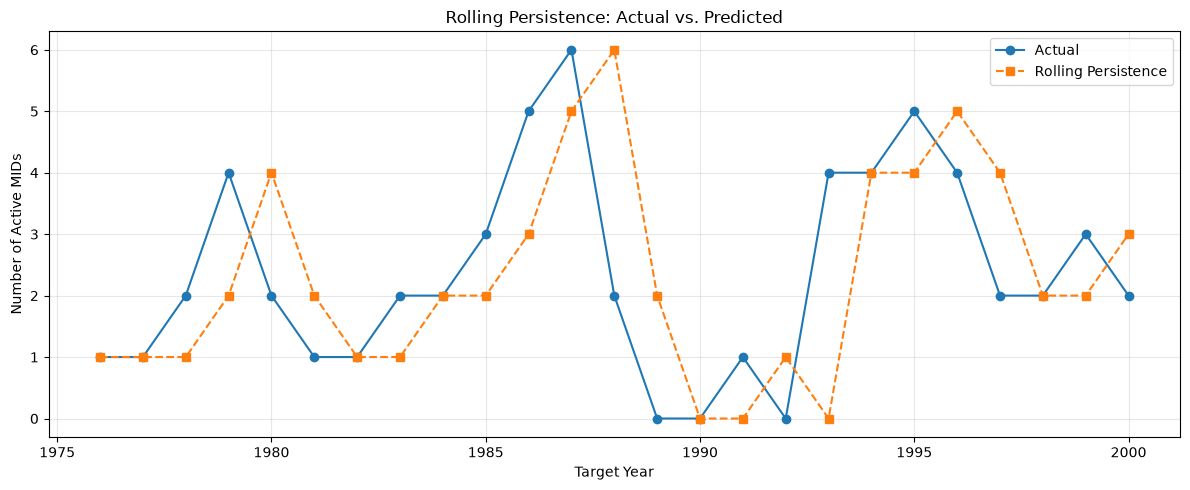

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    persistence_predictions["target_year"],
    persistence_predictions["actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    persistence_predictions["target_year"],
    persistence_predictions["predicted"],
    marker="s",
    linestyle="--",
    label="Rolling Persistence"
)

plt.xlabel("Target Year")
plt.ylabel("Number of Active MIDs")
plt.title("Rolling Persistence: Actual vs. Predicted")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()